# 02 — Entraîner et suivre les modèles

Ce notebook consomme la préparation **v2** du 01. Il ne crée aucune feature et ne lit pas le CSV brut. Chaque modèle est entraîné dans un run MLflow qui couvre `fit` et ses sauvegardes.

Le principal est la référence chargée par le 03 ; les diagnostics restent des runs séparés. Le test est archivé, jamais scoré ici. Les imports sont regroupés, puis les étapes d'exécution suivent l'ordre des sections.

## 1 — Imports et paramètres

MLflow 3.18.0 local ; aucune connexion à un service externe.

In [1]:
import hashlib
import json
import os
import sys
import tempfile
import time
from importlib.metadata import version
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_TELEMETRY", "true")
import matplotlib.pyplot as plt
import mlflow
import mlflow.catboost as mlflow_catboost
import mlflow.data
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from IPython import get_ipython
from IPython.display import display
from mlflow.data.pandas_dataset import from_pandas

# Classe publique générée dynamiquement par MLflow 3.18.
from mlflow.data.sources import (
    LocalArtifactDatasetSource,  # pyright: ignore[reportAttributeAccessIssue]
)
from mlflow.entities import Metric
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    log_loss,
    matthews_corrcoef,
    roc_auc_score,
)

if not Path("settings.py").is_file() and Path("../settings.py").is_file():
    sys.path.insert(0, str(Path.cwd().parent))
from settings import settings

MODEL_PARAMS = {
    "iterations": 1800,
    "depth": 6,
    "learning_rate": 0.035,
    "loss_function": "Logloss",
    "eval_metric": "PRAUC:hints=skip_train~false",
    "l2_leaf_reg": 5,
    "allow_writing_files": False,
    "thread_count": -1,
}
EARLY_STOPPING_ROUNDS = 120
LOG_EVERY = 50
DIAGNOSTIC_ITERATIONS = 400
NOTEBOOK_PATH = settings.PROJECT_ROOT / "notebooks" / "02_churn_modelisation.ipynb"
CONTRACT_PATH = settings.FEATURE_CONTRACT_PATH

## 2 — Vérifier et charger les données

Les SHA-256 empêchent de mélanger une préparation avec d’autres fichiers. Les conversions sont techniques, sans apprentissage.

In [2]:
if not CONTRACT_PATH.is_file():
    raise FileNotFoundError("Exécuter le notebook 01 avant la modélisation.")
preparation = json.loads(CONTRACT_PATH.read_text())
if preparation.get("preparation_schema_version") != 2:
    raise ValueError("Préparation v2 requise ; réexécuter le notebook 01.")
MODEL_FEATURES = preparation["model_features"]
CATEGORICAL_FEATURES = preparation["categorical_features"]
NEW_FEATURES = preparation["new_features"]
SEED = preparation["seed"]
MODEL_PARAMS["random_seed"] = SEED


def verified_path(entry):
    path = settings.PROJECT_ROOT / entry["path"]
    if not path.is_file() or hashlib.sha256(path.read_bytes()).hexdigest() != entry["sha256"]:
        raise ValueError(f"Préparation absente ou modifiée : {path}. Réexécuter le 01.")
    return path


def read_prepared(entry):
    frame = pd.read_csv(
        verified_path(entry),
        dtype={"customer_id": "string", "dept": "string"},
        parse_dates=["snapshot_date", "signup_date"],
    )
    required = set(MODEL_FEATURES) | {"customer_id", "snapshot_date", "churn"}
    if required - set(frame.columns) or len(frame) != entry["rows"]:
        raise ValueError("Schéma ou effectif différent du contrat.")
    if frame.churn.isna().any() or not frame.churn.isin([0, 1]).all() or frame.churn.nunique() != 2:
        raise ValueError("Deux classes binaires renseignées sont requises.")
    if (
        frame[["customer_id", "snapshot_date"]].isna().any().any()
        or frame.duplicated(["customer_id", "snapshot_date"]).any()
    ):
        raise ValueError("Clé client × snapshot invalide.")
    return frame


def make_matrix(frame, features):
    result = frame[features].copy()
    for column in features:
        if column in CATEGORICAL_FEATURES:
            result[column] = result[column].astype("string").fillna("__MISSING__").astype(str)
        else:
            result[column] = (
                pd.to_numeric(result[column], errors="coerce")
                .astype(float)
                .replace([np.inf, -np.inf], np.nan)
            )
    return result


frames = {name: read_prepared(entry) for name, entry in preparation["datasets"].items()}
assert frames["train"].snapshot_date.max() < frames["validation"].snapshot_date.min()
assert frames["validation"].snapshot_date.max() < frames["test"].snapshot_date.min()
verified_path(preparation["source"])
display(
    pd.DataFrame(
        {
            "feature": MODEL_FEATURES,
            "categorical": [c in CATEGORICAL_FEATURES for c in MODEL_FEATURES],
        }
    )
)

,feature,categorical
0,contract,True
1,region,True
2,dept,True
3,channel,True
4,monthly_fee,False
5,data_gb,False
6,support_calls_3m,False
7,late_payments,False
8,nps,False
9,tenure_months,False


## 3 — Configurer MLflow

Une seule configuration pour tous les runs ; pas de serveur permanent.

In [3]:
settings.MLFLOW_DIR.mkdir(parents=True, exist_ok=True)
mlflow.set_tracking_uri(settings.MLFLOW_TRACKING_URI)
client = MlflowClient()
experiment = client.get_experiment_by_name(settings.MLFLOW_EXPERIMENT)
experiment_id = (
    experiment.experiment_id
    if experiment
    else client.create_experiment(
        settings.MLFLOW_EXPERIMENT, artifact_location=(settings.MLFLOW_DIR / "artifacts").as_uri()
    )
)
print("Expérience :", settings.MLFLOW_EXPERIMENT, "— préparation :", preparation["preparation_id"])

Expérience : telco-churn — préparation : c0f381d56f0acd463786fb97b6d5bf0d4555aa50249bec980567fcbd2fdb775d


## 4 — Fonctions de suivi

Ces fonctions ne créent pas de modèle et n'ouvrent pas de run. Elles s'utilisent dans les blocs `with mlflow.start_run(...)` visibles plus bas.

- `log_inputs` : paramètres, source, environnement, copies des données et filiation.
- `LearningCallback` : métriques pendant fit ; `log_results` : historique complet sans doublons, métriques finales et contrat.
- `log_model` : sauvegarde native CatBoost, signature et exemple d'entrée.

Le notebook 03 requiert un run `FINISHED`, `role=principal`, `contract_version=2` et `artifacts_complete=true`. Une exception pendant fit ou la sauvegarde empêche sa sélection.

In [4]:
def run_tags(role, parent=None):
    tags = {"stage": "training", "role": role, "contract_version": "2"}
    if parent:
        tags.update({"mlflow.parentRunId": parent, "parent_training_run_id": parent})
    return tags


def log_inputs(estimator, datasets, features, feature_metadata, cell_id):
    mlflow.log_params(estimator.get_params())
    mlflow.log_params(
        {"preparation_id": preparation["preparation_id"], "feature_count": len(features)}
    )
    manifest = {
        "contract_version": 2,
        "model_features": list(features),
        "categorical_features": [c for c in features if c in CATEGORICAL_FEATURES],
        "new_features": NEW_FEATURES,
        "excluded": preparation["excluded"],
        "feature_metadata": feature_metadata,
        "preparation_id": preparation["preparation_id"],
        "threshold": None,
        "datasets": {},
        "seed": SEED,
    }
    active = mlflow.active_run()
    if active is None:
        raise RuntimeError("Ouvrir un run MLflow avant de logguer les entrées.")
    with tempfile.TemporaryDirectory(prefix="telco-inputs-") as temporary:
        for name, frame in datasets.items():
            path = Path(temporary) / f"{name}.csv"
            frame.to_csv(path, index=False)
            mlflow.log_artifact(str(path), "data")
            manifest["datasets"][name] = {
                "artifact_path": f"data/{name}.csv",
                "rows": len(frame),
                "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
            }
            numeric = make_matrix(frame, features)
            numeric["churn"] = frame.churn.to_numpy(dtype=float)
            dataset = from_pandas(
                numeric,
                name=name,
                targets="churn",
                source=LocalArtifactDatasetSource(f"{active.info.artifact_uri}/data/{name}.csv"),
            )
            mlflow.log_input(
                dataset,
                context={"train": "training", "validation": "validation", "test": "test_reference"}[
                    name
                ],
            )
    snapshot = json.loads(NOTEBOOK_PATH.read_text())
    for cell in snapshot["cells"]:
        if cell["cell_type"] == "code":
            cell.update(outputs=[], execution_count=None)
    mlflow.log_text(json.dumps(snapshot, ensure_ascii=False, indent=1), "source/notebook_02.ipynb")
    cells = [c for c in snapshot["cells"] if c["cell_type"] == "code"]
    mlflow.log_text("\n\n".join("".join(c["source"]) for c in cells), "source/notebook_02.py")
    source = "".join(next(c for c in cells if c["id"] == cell_id)["source"])
    shell = get_ipython()
    if shell is not None and shell.history_manager.input_hist_raw[-1].strip():
        source = shell.history_manager.input_hist_raw[-1]
    mlflow.log_text(source, "source/training_cell.py")
    mlflow.log_artifact(str(verified_path(preparation["source"])), "source/features")
    mlflow.log_dict(preparation, "source/features/feature_contract.json")
    mlflow.log_dict(preparation["quality"], "preparation/quality.json")
    for entry in preparation["reports"].values():
        mlflow.log_artifact(str(verified_path(entry)), "preparation")
    for filename in ["settings.py", "pyproject.toml", "poetry.lock"]:
        path = settings.PROJECT_ROOT / filename
        if path.is_file():
            mlflow.log_artifact(str(path), "source/configuration")
    mlflow.log_dict(
        {
            "python": sys.version,
            "packages": {
                p: version(p) for p in ["mlflow", "catboost", "numpy", "pandas", "scikit-learn"]
            },
        },
        "environment.json",
    )
    return manifest

In [5]:
def metric_key(split, metric):
    return f"learning/{split}/{metric}".lower().replace(":", "_").replace(";", "_")


class LearningCallback:
    def after_iteration(self, info):
        if info.iteration == 1 or info.iteration % LOG_EVERY == 0:
            values = {
                metric_key(split, metric): float(values[-1])
                for split, metrics in info.metrics.items()
                for metric, values in metrics.items()
                if values and np.isfinite(values[-1])
            }
            mlflow.log_metrics(values, step=info.iteration)
        return True


def log_model(estimator, train, features):
    matrix = make_matrix(train, features)
    return mlflow_catboost.log_model(
        estimator,
        name="catboost",
        signature=infer_signature(matrix, estimator.predict(matrix)),
        input_example=matrix.head(5),
        pip_requirements=[
            f"{p}=={version(p)}" for p in ["mlflow", "catboost", "numpy", "pandas", "scikit-learn"]
        ],
    )


def log_results(estimator, manifest, datasets, model_info, threshold=None):
    active = mlflow.active_run()
    if active is None:
        raise RuntimeError("Ouvrir un run MLflow avant de logguer les résultats.")
    manifest.update(model_uri=model_info.model_uri, threshold=threshold)
    mlflow.log_params(
        {
            "best_iteration": estimator.get_best_iteration(),
            "fitted_tree_count": estimator.tree_count_,
        }
    )
    mlflow.log_dict(estimator.get_all_params(), "model/effective_parameters.json")
    if threshold is not None:
        mlflow.log_param("decision_threshold", threshold)
    for name in ["train", "validation"]:
        frame = datasets[name]
        probability = estimator.predict_proba(make_matrix(frame, manifest["model_features"]))[:, 1]
        scores = {
            "average_precision": average_precision_score(frame.churn, probability),
            "roc_auc": roc_auc_score(frame.churn, probability),
            "log_loss": log_loss(frame.churn, probability, labels=[0, 1]),
            "brier": brier_score_loss(frame.churn, probability),
        }
        if threshold is not None:
            scores["mcc"] = matthews_corrcoef(frame.churn, probability >= threshold)
        mlflow.log_metrics(
            {f"{name}_{key}": float(v) for key, v in scores.items()}, model_id=model_info.model_id
        )
    rows, remaining = [], []
    timestamp = int(time.time() * 1000)
    for split, metrics in estimator.get_evals_result().items():
        for metric, values in metrics.items():
            for step, value in enumerate(values, 1):
                if np.isfinite(value):
                    rows.append(
                        {"split": split, "metric": metric, "iteration": step, "value": value}
                    )
                    if step != 1 and step % LOG_EVERY != 0:
                        remaining.append(
                            Metric(metric_key(split, metric), float(value), timestamp, step)
                        )
    for offset in range(0, len(remaining), 1000):
        client.log_batch(active.info.run_id, metrics=remaining[offset : offset + 1000])
    mlflow.flush_async_logging()
    mlflow.log_text(pd.DataFrame(rows).to_csv(index=False), "learning/history.csv")
    mlflow.log_dict(estimator.get_evals_result(), "learning/history.json")
    mlflow.log_dict(manifest, "contract.json")
    mlflow.set_tag("artifacts_complete", "true")

## 5 — Entraîner le principal

Le run couvre les données, fit, le seuil de validation et la sauvegarde. Il n’utilise aucun score de test.

In [6]:
if mlflow.active_run() is not None:
    raise RuntimeError("Terminer le run MLflow actif avant de poursuivre.")
with mlflow.start_run(
    experiment_id=experiment_id, run_name="catboost_principal_v2", tags=run_tags("principal")
) as run:
    training_run_id = run.info.run_id
    model = CatBoostClassifier(**MODEL_PARAMS)
    manifest = log_inputs(
        model, frames, MODEL_FEATURES, preparation["feature_metadata"], "train-principal"
    )
    mlflow.log_params({"early_stopping_rounds": EARLY_STOPPING_ROUNDS, "use_best_model": True})
    started = time.perf_counter()
    model.fit(
        make_matrix(frames["train"], MODEL_FEATURES),
        frames["train"].churn,
        cat_features=CATEGORICAL_FEATURES,
        eval_set=(make_matrix(frames["validation"], MODEL_FEATURES), frames["validation"].churn),
        early_stopping_rounds=EARLY_STOPPING_ROUNDS,
        use_best_model=True,
        verbose=LOG_EVERY,
        callbacks=[LearningCallback()],
    )
    mlflow.log_metric("fit_duration_seconds", time.perf_counter() - started)
    validation_probability = model.predict_proba(make_matrix(frames["validation"], MODEL_FEATURES))[
        :, 1
    ]
    threshold_table = pd.DataFrame({"threshold": np.linspace(0.05, 0.95, 181)})
    threshold_table["mcc"] = [
        matthews_corrcoef(frames["validation"].churn, validation_probability >= t)
        for t in threshold_table.threshold
    ]
    best_threshold = float(
        threshold_table.threshold.to_numpy(dtype=float)[
            int(threshold_table.mcc.to_numpy(dtype=float).argmax())
        ]
    )
    mlflow.log_text(threshold_table.to_csv(index=False), "selection/threshold_scores.csv")
    info = log_model(model, frames["train"], MODEL_FEATURES)
    log_results(model, manifest, frames, info, best_threshold)
print("Principal sauvegardé :", training_run_id)
print("Seuil :", best_threshold)

0:	learn: 0.0523364	test: 0.0442468	best: 0.0442468 (0)	total: 95ms	remaining: 2m 50s
50:	learn: 0.1568217	test: 0.1276615	best: 0.1276615 (50)	total: 2.03s	remaining: 1m 9s
100:	learn: 0.1900385	test: 0.1376315	best: 0.1376315 (100)	total: 4.94s	remaining: 1m 23s
150:	learn: 0.2142330	test: 0.1356564	best: 0.1376315 (100)	total: 7.75s	remaining: 1m 24s
200:	learn: 0.2266630	test: 0.1354752	best: 0.1379037 (169)	total: 9.19s	remaining: 1m 13s
250:	learn: 0.2427705	test: 0.1355336	best: 0.1379037 (169)	total: 10.6s	remaining: 1m 5s
Stopped by overfitting detector  (120 iterations wait)

bestTest = 0.1379037249
bestIteration = 169

Shrink model to first 170 iterations.
Principal sauvegardé : c7b27977db5f4705ac890f88f986389e
Seuil : 0.05


## 6 — Lire l’apprentissage

La perte et la PRAUC ont des échelles différentes. Le modèle sauvegardé conserve les arbres sélectionnés ; les courbes incluent la patience de l’early stopping.

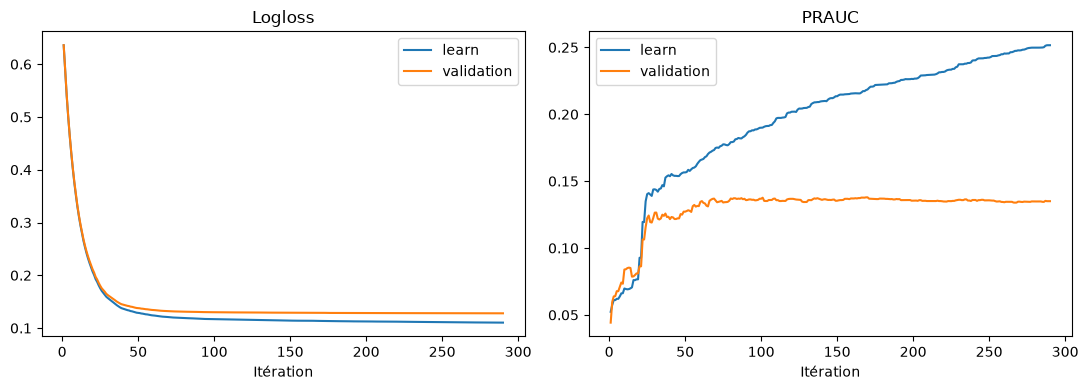

In [7]:
history = model.get_evals_result()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for split in ["learn", "validation"]:
    for ax, metric in zip(axes, ["Logloss", "PRAUC"]):
        values = history.get(split, {}).get(metric, [])
        if values:
            ax.plot(range(1, len(values) + 1), values, label=split)
        ax.set(title=metric, xlabel="Itération")
        ax.legend()
fig.tight_layout()
plt.show()
client.log_figure(training_run_id, fig, "learning/curves.png")

## 7 — Diagnostics temporels et par client

Les features de chaque protocole sont déjà préparées par le 01. Les runs portent `role=diagnostic` et ne remplacent jamais le principal. Un modèle à nombre d'arbres fixé n'utilise pas le jeu de contrôle pour l'early stopping.

In [8]:
diagnostic_entries = [("clients_jamais_vus", preparation["diagnostics"]["clients"])]
diagnostic_entries += [
    (f"walk_{entry['month']}", entry) for entry in preparation["diagnostics"]["walk_forward"]
]
diagnostic_scores = []
for name, entry in diagnostic_entries:
    diagnostic_frames = {label: read_prepared(meta) for label, meta in entry["datasets"].items()}
    with mlflow.start_run(
        experiment_id=experiment_id, run_name=name, tags=run_tags("diagnostic", training_run_id)
    ) as run:
        estimator = CatBoostClassifier(
            iterations=DIAGNOSTIC_ITERATIONS,
            depth=6,
            learning_rate=0.035,
            loss_function="Logloss",
            random_seed=SEED,
            allow_writing_files=False,
            thread_count=-1,
        )
        diagnostic_manifest = log_inputs(
            estimator,
            diagnostic_frames,
            MODEL_FEATURES,
            entry["feature_metadata"],
            "train-diagnostics",
        )
        estimator.fit(
            make_matrix(diagnostic_frames["train"], MODEL_FEATURES),
            diagnostic_frames["train"].churn,
            cat_features=CATEGORICAL_FEATURES,
            verbose=False,
            callbacks=[LearningCallback()],
        )
        diagnostic_info = log_model(estimator, diagnostic_frames["train"], MODEL_FEATURES)
        log_results(estimator, diagnostic_manifest, diagnostic_frames, diagnostic_info)
        probability = estimator.predict_proba(
            make_matrix(diagnostic_frames["validation"], MODEL_FEATURES)
        )[:, 1]
        diagnostic_scores.append(
            {
                "protocol": name,
                "run_id": run.info.run_id,
                "average_precision": average_precision_score(
                    diagnostic_frames["validation"].churn, probability
                ),
                "roc_auc": roc_auc_score(diagnostic_frames["validation"].churn, probability),
            }
        )
display(pd.DataFrame(diagnostic_scores))

,protocol,run_id,average_precision,roc_auc
0,clients_jamais_vus,7bd36dd12ad74d99a78c21d9f83fb63e,0.130131,0.774438
1,walk_2024-08,a519fdac2be44db4a7f7fa4d3df7a702,0.155987,0.782183
2,walk_2024-09,d31caa991399483fa40c73fdbe3eb932,0.122708,0.794640
3,walk_2024-10,d2fdacc614ef4ffe86c674b2c03e88aa,0.135381,0.790586
4,walk_2024-11,72feaddf8eca40178c72f499996e5bb2,0.164887,0.792727


## 8 — Suite de l'étude

Ouvrir le notebook 03 dans un noyau neuf pour évaluer et expliquer le principal sauvegardé. Les ablations de variables devront comparer des familles métier sur les mêmes périodes, sans consulter le test pour choisir. Les ablations de facture de la première version restent dans les anciens runs ; cette refonte ne réintroduit pas ces variables suspectes dans la référence.